# Iris Classification: Logistic Regression vs Decision Tree
Classify iris flowers into 3 species and compare two models using accuracy, precision, recall and F1-score.

**Steps:** load data → explore → scale & split (80/20) → train → evaluate → visualise

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.inspection import DecisionBoundaryDisplay

sns.set_theme(style="whitegrid")

## 2. Load and Explore the Data
Download the dataset first if you don't have it: `curl -o iris.csv https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv`

In [2]:
df = pd.read_csv("iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
print(df["species"].value_counts())

Shape: (150, 5)
Missing values: 0
Duplicate rows: 1

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Pairplot
Petal measurements separate the species much better than sepal measurements.

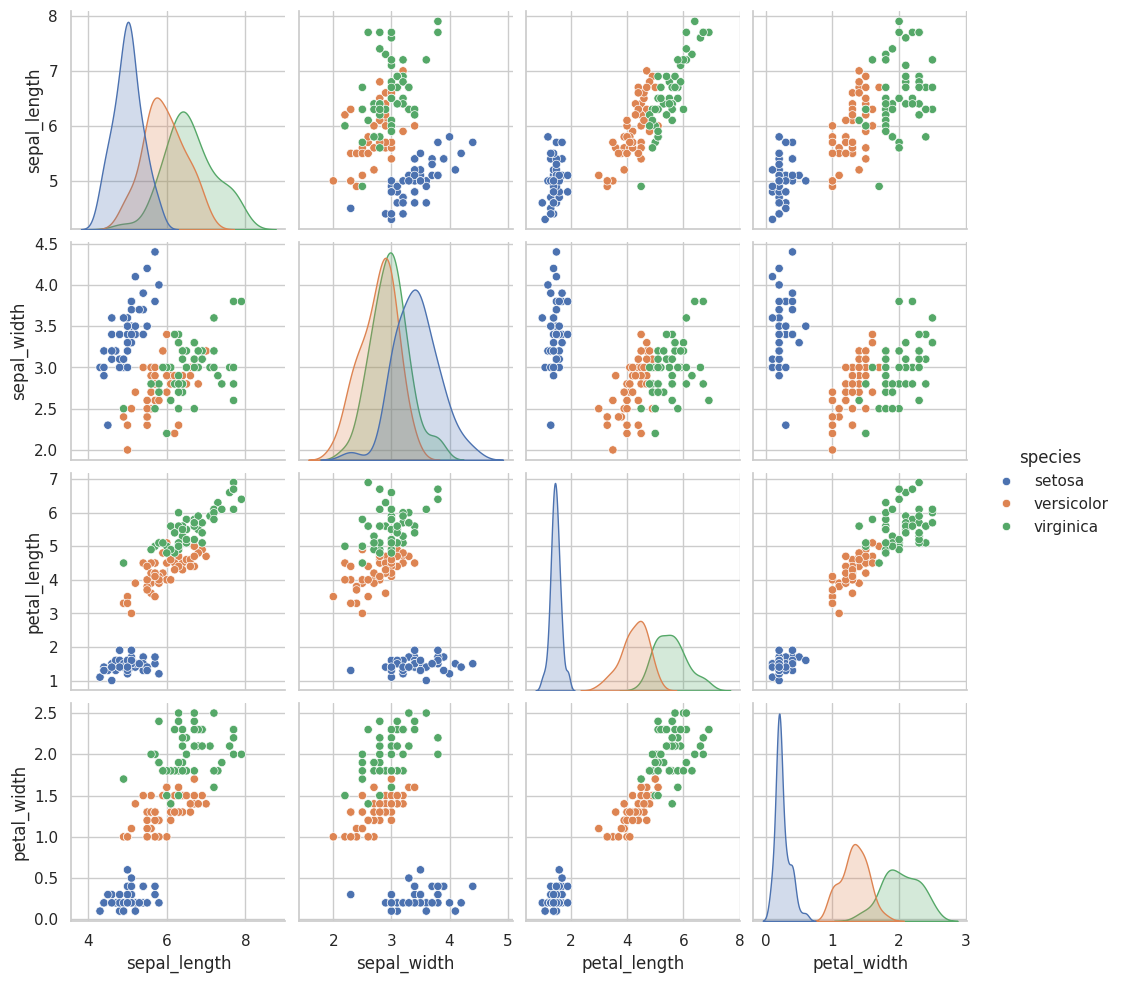

In [5]:
sns.pairplot(df, hue="species", diag_kind="kde")
plt.show()

## 3. Prepare the Data
- Encode species names as numbers
- Split 80/20 (`stratify` keeps the class balance equal in both sets)
- Scale features: the scaler is fit on **train only** to avoid data leakage

In [6]:
X = df.drop(columns="species")
encoder = LabelEncoder()
y = encoder.fit_transform(df["species"])
class_names = encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (120, 4) | Test: (30, 4)


## 4. Train the Models

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
}

preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds[name] = model.predict(X_test_s)

## 5. Evaluate the Models

### Benchmark table (test set, macro-averaged)

In [8]:
rows = []
for name, pred in preds.items():
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro")
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": p, "Recall": r, "F1-score": f1})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.967,0.970,0.967,0.967


### Per-class report

In [9]:
for name, pred in preds.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, pred, target_names=class_names))

--- Logistic Regression ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

--- Decision Tree ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Cross-validation
The test set has only 30 samples, so one mistake changes accuracy by 3.3%. 5-fold cross-validation gives a more reliable score. 
A `Pipeline` re-fits the scaler inside each fold, so there is no leakage.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=cv)
    print(f"{name}: {scores.mean():.2%} (+/- {scores.std():.2%})")

Logistic Regression: 95.33% (+/- 4.52%)
Decision Tree: 96.00% (+/- 2.49%)


## 6. Confusion Matrices

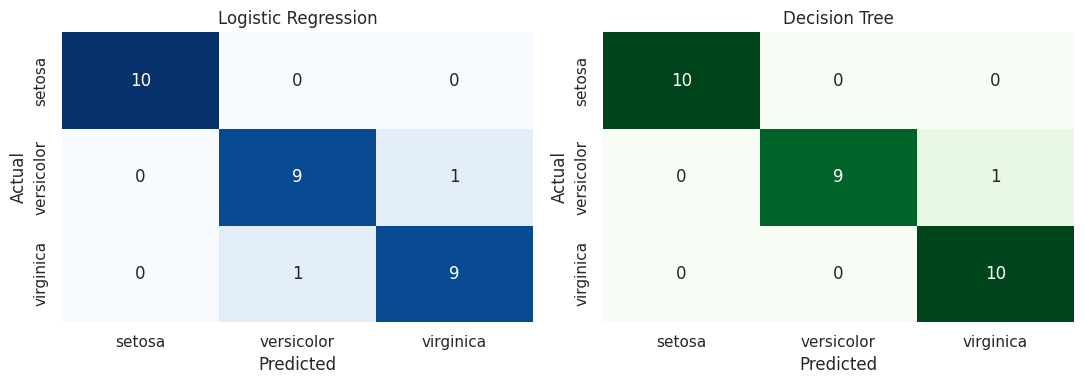

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, pred), cmap in zip(axes, preds.items(), ["Blues", "Greens"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, cmap=cmap, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")

plt.tight_layout()
plt.show()

## 7. Decision Boundaries
Boundaries can only be drawn in 2-D, so these two models use just **petal length** and **petal width** (the most useful features). They are separate from the 4-feature models above.

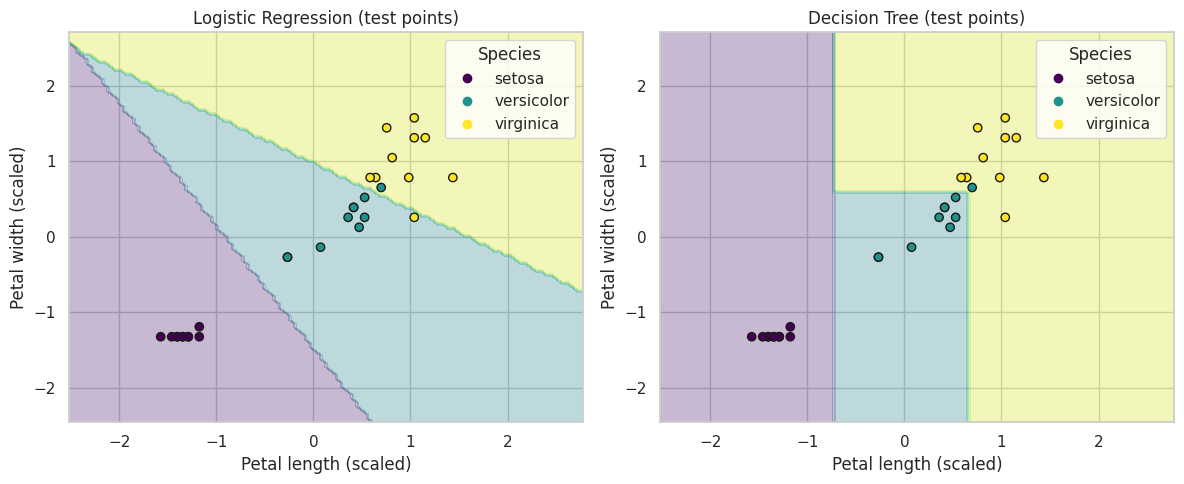

In [12]:
cols = [2, 3]  # petal_length, petal_width
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    model_2d = model.__class__(**model.get_params()).fit(X_train_s[:, cols], y_train)

    DecisionBoundaryDisplay.from_estimator(model_2d, X_train_s[:, cols], response_method="predict",
                                           cmap="viridis", alpha=0.3, ax=ax)
    scatter = ax.scatter(X_test_s[:, 2], X_test_s[:, 3], c=y_test, cmap="viridis", edgecolors="k")
    ax.set(title=f"{name} (test points)",
           xlabel="Petal length (scaled)", ylabel="Petal width (scaled)")
    ax.legend(scatter.legend_elements()[0], class_names, title="Species")

plt.tight_layout()
plt.show()

## 8. Conclusion
- *Setosa* is perfectly separable; all mistakes are between *versicolor* and *virginica*.
- Logistic Regression draws smooth straight boundaries, while the Decision Tree draws step-like boxes.
- Both models score about the same in cross-validation, so neither is clearly better on this small, clean dataset.
- Possible next steps: try KNN / SVM / Random Forest and tune with `GridSearchCV`.